# Advanced Image Reconstruction

**Part:** J – Advanced & fun topics · **Reading time:** ~60 min · **Pass 1 overview:** [Speed, artifacts and safety](../pass1_big_picture/P1.5_Speed_Artifacts_and_Safety.ipynb) · **Prerequisites:** [F3 Image reconstruction](F3_Image_Reconstruction.ipynb), [H3 Accelerated imaging methods](H3_Accelerated_Imaging_Methods.ipynb) · **Refreshers you may want:** [Continuous FT ↔ DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [2D Fourier & images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

This chapter introduces a more general formulation of image reconstruction in MRI: **reconstruction as solving a linear inverse problem**. This one formulation describes the basic Fourier reconstruction and a variety of advanced methods: parallel imaging, compressed sensing and deep-learning reconstruction.

**Why this chapter matters.** Modern scanners rarely reconstruct with a single inverse FFT any more. Accelerated clinical protocols run iterative solvers or trained networks on GPUs inside the scanner. The language used to describe all of them, "encoding operator", "data consistency", "regularizer", is introduced here, and every method is implemented in a few lines of numpy so you can see it work.

## Learning goals

1. Describe how images are formed
    * Formulate MRI reconstruction as a linear system $y = \mathbf E x + n$
    * Describe the encoding operators of Fourier, parallel-imaging and compressed-sensing reconstructions
2. *(added)* Explain why the encoding matrix is applied as an *operator* (with FFTs) and never stored.
3. *(added)* Solve the SENSE least-squares problem iteratively with conjugate gradients, and see the effect of Tikhonov regularization on noise.
4. *(added)* Implement a compressed-sensing (ℓ1-wavelet) reconstruction with the FISTA algorithm.
5. *(added)* Understand unrolled deep-learning reconstructions as "iterative algorithms with learned steps", including their requirements and risks.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | Size / unit | Remark |
|---|---|---|---|
| $x$ | the unknown image, **vectorized** (all pixels stacked in one column) | $N_{pix}$ complex values | here $x = m(\vec r_j)$, the transverse magnetization at pixel $j$ |
| $y$ | all measured k-space samples, stacked | $N_{meas}$ complex values | from all TRs (and all coils) |
| $n$ | measurement noise | same as $y$ | complex Gaussian |
| $\mathbf E$ | **encoding matrix/operator**: maps an image to the data it would produce | $N_{meas}\times N_{pix}$ | derived from the signal equation |
| $\mathbf F$ | (discrete) Fourier transform matrix, $\mathbf F_{i,j} = e^{-i2\pi\vec k_i\cdot\vec r_j}$ | $N_k\times N_{pix}$ | applied with the FFT |
| $\vec k_i$, $\vec r_j$ | k-space location of sample $i$; position of pixel $j$ | m⁻¹, m | |
| $\mathbf C_q$ | diagonal matrix holding the sensitivity of receive coil $q$ at each pixel | $N_{pix}\times N_{pix}$ | $q = 1\dots N_c$ |
| $N_c$ | number of receive coils | – | 8 here |
| $\mathbf S$ | k-space sub-sampling operator: keeps sampled locations, drops the rest | – | entries 0 or 1 |
| $R$ | acceleration (undersampling) factor | – | 2–8 |
| $\mathbf A^H$ | conjugate transpose (Hermitian adjoint) of a matrix $\mathbf A$ | – | for $\mathbf F$: the inverse DFT up to a factor |
| $\lVert v\rVert_2$, $\lVert v\rVert_1$ | Euclidean norm $\sqrt{\sum\lvert v_i\rvert^2}$; ℓ1 norm $\sum\lvert v_i\rvert$ | – | |
| $\hat x$ | the reconstructed estimate of $x$ | – | |
| $\arg\min_x f(x)$ | "the $x$ that makes $f(x)$ smallest" | – | |
| $\lambda$, $\lambda_{CS}$ | regularization weights | – | tuned |
| $\mathbf W$ | sparsifying transform (here: orthonormal 2D Haar wavelet) | – | also TV, other wavelets |
| $\mathbf G$, $\mathbf I$ | calibration (k-space interpolation) kernel operator; identity matrix | – | GRAPPA/SPIRiT |
| $\mathcal R(x)$ | general regularizer (penalty on implausible images) | – | may be learned |
| $g_{DNN}$, $\mathcal N_w$ | a deep neural network; with learned weights $w$ | – | |
| $\mathrm{soft}_\tau(v)$ | soft-thresholding: shrink magnitude by $\tau$, zero if below | – | proximal operator of the ℓ1 norm |
| $L$, $t$ | Lipschitz constant of the data-term gradient; step size ($t\le 1/L$) | – | |

> **⚠️ Common confusion:** In this chapter $x$ is the **image vector**, not the x-coordinate, and $y$ is the **data vector**, not the y-coordinate. This is the standard linear-algebra notation used in the reconstruction literature; positions are written $\vec r_j$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. General formulation of MRI reconstruction

For advanced image reconstruction methods it is helpful to write the reconstruction problem as a linear system:

$$y = \mathbf E x + n$$

where $y$ is the acquired data, $\mathbf E$ is the encoding matrix, $x$ is the spatial distribution of the transverse magnetization (the image), and $n$ is noise. In this formulation the image is **vectorized**: the 2D array of pixels is stacked into one long column.

**In words:** "the data equal the encoding applied to the image, plus noise". Reconstruction means: given $y$ and a model $\mathbf E$ of the scanner, find $x$.

## 2. Fourier transform reconstruction

The definition of $\mathbf E$ is critical, and it comes from the MRI signal equation ([C2](C2_MRI_Signal_Equation.ipynb)). If we only consider the effects of the magnetic field gradients,

$$s(t) = \int m(\vec r)\,e^{-i2\pi\vec k(t)\cdot\vec r}\,d\vec r$$

Our measurements $y$ are samples of $s(t)$ at discrete time points. For Cartesian sampled data:

$$ y = \begin{bmatrix} s_1(t_1) \\ s_1(t_2) \\ \vdots \\ s_1(t_{N_x}) \\ s_2(t_1) \\ \vdots \\ s_{N_y}(t_{N_x})\end{bmatrix}$$

where $s_m(t_n)$ is the data from repetition (TR) $m$ at readout sample $n$. We want to reconstruct the image on a grid:

$$ x = \begin{bmatrix} m(x_1,y_1) \\ m(x_2,y_1) \\ \vdots \\ m(x_{N_x},y_1) \\ m(x_1,y_2) \\ \vdots \\ m(x_{N_x},y_{N_y})\end{bmatrix}$$

where $(x_i, y_j)$ are equally spaced locations in image space. Replacing the integral by a sum over pixels gives the **DFT matrix** $\mathbf F$, with entries determined by the sampled k-space location $\vec k_i$ and the pixel location $\vec r_j$:

$$\mathbf F_{i,j} = e^{-i2\pi\vec k_i\cdot\vec r_j}$$

so that

$$y = \mathbf F x + n$$

For fully sampled Cartesian data on the grid $\Delta k = 1/FOV$, the columns of $\mathbf F$ are orthogonal: $\mathbf F^H\mathbf F = N_{pix}\,\mathbf I$. The inverse is therefore

$$\hat x = \mathbf F^{-1}y = \frac{1}{N_{pix}}\,\mathbf F^H y$$

**In words:** for full Cartesian sampling, the reconstruction is the inverse DFT, computed with the FFT in $O(N\log N)$ operations instead of the $O(N^2)$ of a matrix product. (The original text writes $\hat x = \mathbf F^H y$, which is correct only for the *unitary* normalization $\mathbf F/\sqrt{N_{pix}}$, used by `mt.fft2c` with `norm="ortho"`.)

In [2]:
# 1D check: build the DFT matrix explicitly and compare with the FFT
N = 64
k = (np.arange(N) - N // 2) / N              # k in cycles per pixel (FOV = N pixels)
r = np.arange(N) - N // 2                    # pixel positions
F = np.exp(-1j * 2 * np.pi * np.outer(k, r))
x_true = np.zeros(N); x_true[20:40] = 1; x_true[28:32] = 2
y_data = F @ x_true
print("F^H F = N I ?            ", np.allclose(F.conj().T @ F, N * np.eye(N)))
print("F x == centred FFT ?     ", np.allclose(y_data, mt.fftc(x_true, norm=None)))
print("(1/N) F^H y recovers x ? ", np.allclose(F.conj().T @ y_data / N, x_true))
print(f"memory of E for a 256x256 image with 8 coils: {(256**2)**2 * 8 * 16 / 1e9:.0f} GB  -> never stored!")

F^H F = N I ?             True
F x == centred FFT ?      True
(1/N) F^H y recovers x ?  True
memory of E for a 256x256 image with 8 coils: 550 GB  -> never stored!


**Interpretation.** The matrix picture and the FFT give identical results. For real image sizes, $\mathbf E$ would need hundreds of gigabytes, so iterative methods never build it. They only need two functions: one that applies $\mathbf E$ (image → data) and one that applies $\mathbf E^H$ (data → image), both made of FFTs and pixel-wise multiplications.

## 3. Parallel imaging as a linear inverse problem

For parallel imaging (PI) we include in our model the **coil sensitivity profiles** $\mathbf C_q$ of each receive coil, together with the Fourier encoding $\mathbf F$. For undersampled acquisitions we add a k-space **sub-sampling operator** $\mathbf S$. This states explicitly that the Nyquist criterion is *not* met for the skipped locations, and it lets us still compute $\mathbf F$ and $\mathbf F^H$ with the FFT on the full grid. With these factors, the data from coil $q$ are

$$y_q = \mathbf E_q x + n_q = \mathbf S\,\mathbf F\,\mathbf C_q\,x + n_q$$

* $\mathbf C_q$ is a **diagonal** matrix: multiply each pixel by the coil's sensitivity there.
* $\mathbf S$ is a diagonal matrix of 1s and 0s: 1 if that grid location was sampled.

Stacking all coils (concatenating along the coil dimension) gives back the general form:

$$\mathbf y = \begin{bmatrix} y_1\\ \vdots\\ y_{N_c}\end{bmatrix},\quad
\mathbf E = \begin{bmatrix} \mathbf E_1\\ \vdots\\ \mathbf E_{N_c}\end{bmatrix},\quad
\mathbf n = \begin{bmatrix} n_1\\ \vdots\\ n_{N_c}\end{bmatrix}
\qquad\Rightarrow\qquad \mathbf y = \mathbf E x + \mathbf n$$

Let's set this up in code: a phantom, 8 simulated loop coils, and the operators $\mathbf E$ and $\mathbf E^H$.

adjoint test: True
E^H E = I for full sampling: True


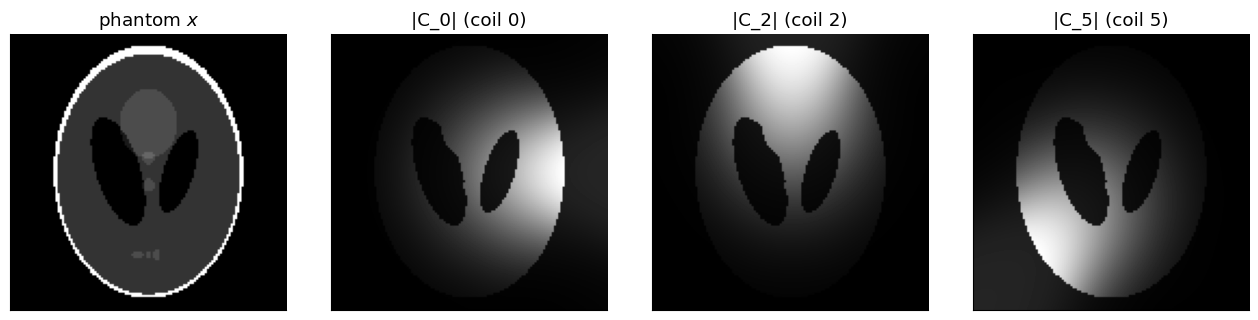

In [3]:
N = 128
FOV = 0.24                                           # m
x_true = mt.shepp_logan(N).astype(complex)
xx = (np.arange(N) - N // 2) * FOV / N
X, Y = np.meshgrid(xx, -xx)                          # image row 0 = top (+y)
pts = np.stack([X, Y, np.zeros_like(X)], axis=-1)

def coil_maps(n_coils=8, radius=0.06, dist=0.14):
    """Receive sensitivities C ~ (Bx - i By) of loop coils arranged on a circle around the object.
    Each loop's axis points to the centre. Normalized so that sum_q |C_q|^2 = 1 at every pixel."""
    maps = []
    for a in 2 * np.pi * np.arange(n_coils) / n_coils:
        Rm = mt.Rz(-a)                               # rotate the world so this coil sits on the +x axis
        p = pts @ Rm.T
        B = mt.loop_coil_field(p, radius, 1.0, center=(dist, 0, 0), normal="x")
        B = B @ mt.Rz(a).T                           # rotate the field back
        maps.append(B[..., 0] - 1j * B[..., 1])
    C = np.array(maps)
    return C / np.sqrt(np.sum(np.abs(C) ** 2, axis=0))

C = coil_maps()

def E(x, mask):
    """Encoding: image (N,N) -> undersampled multi-coil k-space (Nc,N,N); unsampled entries are 0."""
    return mask * mt.fft2c(C * x)

def EH(y, mask):
    """Adjoint: multi-coil k-space -> image; inverse FFT then coil-combine with conj(C)."""
    return np.sum(np.conj(C) * mt.ifft2c(mask * y), axis=0)

# adjoint test: <E x, y> must equal <x, E^H y> for random x, y
rng = np.random.default_rng(1)
mask_full = np.ones((N, N))
xr = rng.standard_normal((N, N)) + 1j * rng.standard_normal((N, N))
yr = rng.standard_normal((8, N, N)) + 1j * rng.standard_normal((8, N, N))
print("adjoint test:", np.allclose(np.vdot(E(xr, mask_full), yr), np.vdot(xr, EH(yr, mask_full))))
print("E^H E = I for full sampling:", np.allclose(EH(E(x_true, mask_full), mask_full), x_true))

fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
mt.show_image(x_true, ax=ax[0], title="phantom $x$")
for j, q in enumerate((0, 2, 5)):
    mt.show_image(np.abs(C[q]) * (np.abs(x_true) > 0.01) + 0.15 * np.abs(C[q]), ax=ax[j + 1], title=f"|C_{q}| (coil {q})")
plt.tight_layout(); plt.show()

**Interpretation.** Each coil "sees" mostly the part of the object close to it. Because the maps are normalized ($\sum_q|\mathbf C_q|^2=1$) and the FFT is unitary, $\mathbf E^H\mathbf E=\mathbf I$ for full sampling: the coil-combined inverse FFT is the exact reconstruction. The **adjoint test** is the first thing to check whenever you write your own operators; iterative solvers silently produce garbage if $\mathbf E^H$ is not the true adjoint.

### 3.1 Model-based methods: SENSE as least squares

Model-based parallel imaging methods (SENSE, ESPIRiT, NLINV) use a model of the MRI system and reconstruct a single underlying image by solving an optimization problem. SENSE solves

$$\hat x_{PI} = \arg\min_x \tfrac12\,\lVert \mathbf y - \mathbf E x\rVert_2^2$$

**In words:** find the image whose predicted data best match the measured data (in the least-squares sense). This is called **data consistency**.

Setting the gradient to zero gives the *normal equations* $\mathbf E^H\mathbf E\,x = \mathbf E^H\mathbf y$, with the formal solution (pseudo-inverse)

$$\hat x_{PI} = (\mathbf E^H\mathbf E)^{-1}\mathbf E^H\mathbf y$$

This requires measured coil sensitivity maps to build $\mathbf E$. For Cartesian undersampling, $\mathbf E^H\mathbf E$ decouples into small systems per aliased pixel group (the classic SENSE unfolding in [H3](H3_Accelerated_Imaging_Methods.ipynb)). For general sampling patterns one uses an iterative solver such as **conjugate gradients (CG)**, which only needs the operator $x\mapsto\mathbf E^H\mathbf E x$.

<details><summary><b>📐 Conjugate gradients in one paragraph (optional)</b></summary>

CG solves $\mathbf A x = b$ for a Hermitian positive-definite $\mathbf A$ (here $\mathbf A = \mathbf E^H\mathbf E + \lambda\mathbf I$, $b = \mathbf E^H\mathbf y$). Starting from $x_0=0$, it keeps a residual $r = b - \mathbf A x$ and a search direction $p$. At each step it moves along $p$ by the exact amount that minimizes the quadratic error along that line, then builds the next direction to be "conjugate" ($p_{new}^H\mathbf A p_{old}=0$) to all previous ones. In exact arithmetic it converges in at most $N_{pix}$ steps, and in practice to a useful accuracy in 10–50.

</details>

The term $\lambda\lVert x\rVert_2^2$ (Tikhonov regularization) can be added to tame noise amplification: $\hat x = \arg\min_x \tfrac12\lVert\mathbf y-\mathbf Ex\rVert_2^2 + \tfrac\lambda2\lVert x\rVert_2^2$.

effective acceleration: 2.37


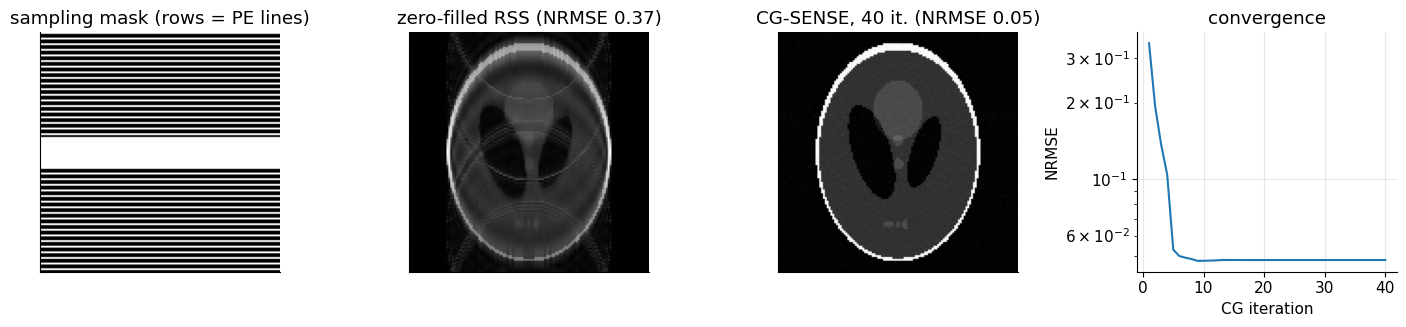

In [4]:
def cg_sense(y, mask, lam=0.0, n_iter=30, x_ref=None):
    """Solve (E^H E + lam I) x = E^H y with conjugate gradients. Returns x and the error history (if x_ref)."""
    A = lambda v: EH(E(v, mask), mask) + lam * v
    b = EH(y, mask)
    x = np.zeros_like(b); r = b.copy(); p = r.copy(); rs = np.vdot(r, r).real
    errs = []
    for _ in range(n_iter):
        Ap = A(p)
        alpha = rs / np.vdot(p, Ap).real
        x = x + alpha * p
        r = r - alpha * Ap
        rs_new = np.vdot(r, r).real
        p = r + (rs_new / rs) * p
        rs = rs_new
        if x_ref is not None:
            errs.append(nrmse(x, x_ref))
    return x, errs

def nrmse(x, ref):
    return np.linalg.norm(np.abs(x) - np.abs(ref)) / np.linalg.norm(np.abs(ref))

# Uniform undersampling R = 3 in the phase-encoding (vertical) direction + 16 fully sampled centre lines
R = 3
mask_u = np.zeros((N, N)); mask_u[::R, :] = 1; mask_u[N // 2 - 8:N // 2 + 8, :] = 1
sigma = 0.004
y_u = mask_u * mt.add_complex_noise(E(x_true, np.ones((N, N))), sigma, rng=np.random.default_rng(2))

x_zf = np.sqrt(np.sum(np.abs(mt.ifft2c(y_u)) ** 2, axis=0))      # zero-filled root-sum-of-squares
x_cg, err_cg = cg_sense(y_u, mask_u, n_iter=40, x_ref=x_true)
print(f"effective acceleration: {mask_u.size / mask_u.sum():.2f}")

fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
mt.show_image(mask_u, ax=ax[0], title="sampling mask (rows = PE lines)")
mt.show_image(x_zf, ax=ax[1], title=f"zero-filled RSS (NRMSE {nrmse(x_zf, x_true):.2f})")
mt.show_image(x_cg, ax=ax[2], title=f"CG-SENSE, 40 it. (NRMSE {nrmse(x_cg, x_true):.2f})")
ax[3].semilogy(np.arange(1, 41), err_cg); ax[3].set_xlabel("CG iteration"); ax[3].set_ylabel("NRMSE")
ax[3].set_title("convergence"); plt.tight_layout(); plt.show()

**Interpretation.** Without a model, the skipped lines produce threefold aliasing (copies of the object overlapping). Solving the SENSE least-squares problem with CG removes the aliasing within a few iterations, because the coil sensitivities provide the missing spatial information. The error plateaus at a level set by **noise amplification** (the g-factor of [H3](H3_Accelerated_Imaging_Methods.ipynb)). It can even rise again with more iterations: CG starts fitting the noise. This "semi-convergence" is why iterative reconstructions are often stopped early or regularized.

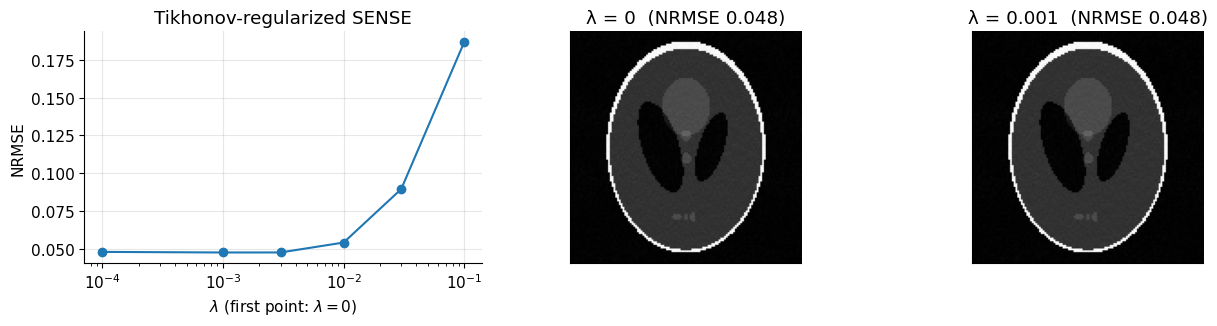

In [5]:
lams = [0, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
errs = []
for lam in lams:
    xl, _ = cg_sense(y_u, mask_u, lam=lam, n_iter=40)
    errs.append(nrmse(xl, x_true))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].semilogx([1e-4] + lams[1:], errs, "o-"); ax[0].set_xlabel(r"$\lambda$ (first point: $\lambda = 0$)")
ax[0].set_ylabel("NRMSE"); ax[0].set_title("Tikhonov-regularized SENSE")
for a_, lam in zip(ax[1:], (0, lams[int(np.argmin(errs))])):
    xl, _ = cg_sense(y_u, mask_u, lam=lam, n_iter=40)
    mt.show_image(xl, ax=a_, title=f"λ = {lam:g}  (NRMSE {nrmse(xl, x_true):.3f})")
plt.tight_layout(); plt.show()

**Interpretation.** A small $\lambda$ suppresses the amplified noise; too large a $\lambda$ biases the image toward zero (loss of contrast). Choosing $\lambda$ is the basic **bias–variance trade-off** that every regularized reconstruction, including deep learning, has to make.

### 3.2 Linear predictability methods: GRAPPA and SPIRiT

Linear-predictability parallel imaging methods (AUTO-SMASH, GRAPPA, SPIRiT) assume that **each k-space sample is a linear combination of its neighbours** (in all coils). This works because multiplying by smooth coil sensitivities in image space is a convolution with a small kernel in k-space ([RM4](../refreshers/RM4_Fourier_Properties.ipynb)). A calibration kernel, computed from the fully sampled centre of k-space and collected in the operator $\mathbf G$, captures this. The general formulation is

$$\hat x_{PI} = \arg\min_x \lVert \mathbf y - \mathbf E x\rVert_2^2 + \lambda\,\lVert(\mathbf G - \mathbf I)\,x\rVert_2^2$$

where $\lambda$ is a tuning (regularization) parameter and $\mathbf I$ the identity. **In words:** be consistent with the measured data (first term) *and* with the calibration (second term: applying the kernel should not change the data). Here $x$ is best thought of as the multi-coil k-space itself.

The kernel $\mathbf G$ can be applied directly to fill in missing data, as in **GRAPPA**, or enforced iteratively while solving the optimization, as in **SPIRiT**. A working GRAPPA example is in [H3](H3_Accelerated_Imaging_Methods.ipynb).

> **TODO (polish):** Add a compact SPIRiT implementation (calibration + CG on the consistency objective) to complement the GRAPPA demo in H3.

## 4. Compressed sensing

Compressed sensing (CS) is formulated as the optimization problem

$$\hat x_{CS} = \arg\min_x \tfrac12\,\lVert\mathbf y-\mathbf E x\rVert_2^2 + \lambda_{CS}\,\lVert\mathbf W x\rVert_1$$

where $\lVert v\rVert_1=\sum_i |v_i|$ is the ℓ1 norm. The first term is **data consistency**. The second term enforces that the image is **sparse** in some domain, through the sparsifying transform $\mathbf W$. The regularization factor $\lambda_{CS}$ balances the two terms.

**Why the ℓ1 norm?** Minimizing $\lVert\cdot\rVert_1$ drives many coefficients exactly to zero (unlike $\lVert\cdot\rVert_2$, which only makes them small). It is the convex stand-in for "use as few non-zero coefficients as possible".

Popular sparsifying transforms $\mathbf W$ include total variation (TV, the image gradient), total generalized variation (TGV), and **wavelets**, in which MRI images are typically sparse. CS needs **incoherent** undersampling: random-like sampling so that aliasing looks like noise, which the sparsity term can remove, instead of coherent copies. The regularization $\lVert\mathbf W x\rVert_1$ can also be combined with parallel imaging, as in the ℓ1-ESPIRiT method; our $\mathbf E$ below already includes the coils ("ℓ1-SENSE").

### 4.1 Solving it: FISTA

The ℓ1 term is not differentiable, so we use a **proximal gradient** method. Each iteration takes a gradient step on the data term and then applies **soft-thresholding** to the wavelet coefficients:

$$x \leftarrow \mathbf W^H\,\mathrm{soft}_{t\lambda}\!\Big(\mathbf W\big(x - t\,\mathbf E^H(\mathbf E x-\mathbf y)\big)\Big), \qquad \mathrm{soft}_\tau(v) = \frac{v}{|v|}\max(|v|-\tau, 0)$$

with step size $t\le 1/L$, where $L$ is the largest eigenvalue of $\mathbf E^H\mathbf E$ (here $L\le1$ thanks to our normalization). This is **ISTA**; **FISTA** adds a momentum step that makes it converge much faster.

In [6]:
def haar2(x, levels=4):
    """Orthonormal multi-level 2D Haar wavelet transform (N must be divisible by 2**levels)."""
    c = x.copy(); n = x.shape[0]
    for _ in range(levels):
        a = c[:n, :n]
        lo = (a[0::2] + a[1::2]) / np.sqrt(2); hi = (a[0::2] - a[1::2]) / np.sqrt(2)
        a = np.concatenate([lo, hi], axis=0)
        lo = (a[:, 0::2] + a[:, 1::2]) / np.sqrt(2); hi = (a[:, 0::2] - a[:, 1::2]) / np.sqrt(2)
        c[:n, :n] = np.concatenate([lo, hi], axis=1)
        n //= 2
    return c

def ihaar2(c, levels=4):
    """Inverse of haar2."""
    x = c.copy(); n = c.shape[0] // 2 ** (levels - 1)
    for _ in range(levels):
        a = x[:n, :n]; h = n // 2
        lo, hi = a[:, :h], a[:, h:]
        b = np.empty_like(a); b[:, 0::2] = (lo + hi) / np.sqrt(2); b[:, 1::2] = (lo - hi) / np.sqrt(2)
        lo, hi = b[:h], b[h:]
        a2 = np.empty_like(b); a2[0::2] = (lo + hi) / np.sqrt(2); a2[1::2] = (lo - hi) / np.sqrt(2)
        x[:n, :n] = a2
        n *= 2
    return x

def soft(v, tau):
    mag = np.abs(v)
    return v * np.maximum(mag - tau, 0) / np.where(mag == 0, 1, mag)

def fista_l1(y, mask, lam, n_iter=100, x_ref=None):
    t = 1.0                                  # step size (L <= 1)
    x = np.zeros((N, N), complex); z = x.copy(); s = 1.0; errs = []
    for _ in range(n_iter):
        grad = EH(E(z, mask) - y, mask)
        x_new = ihaar2(soft(haar2(z - t * grad), t * lam))
        s_new = (1 + np.sqrt(1 + 4 * s**2)) / 2
        z = x_new + ((s - 1) / s_new) * (x_new - x)      # momentum (the "F" in FISTA)
        x, s = x_new, s_new
        if x_ref is not None:
            errs.append(nrmse(x, x_ref))
    return x, errs

print("Haar transform is orthonormal:", np.allclose(ihaar2(haar2(x_true)), x_true),
      " | fraction of wavelet coefficients > 1% of max:",
      f"{np.mean(np.abs(haar2(x_true)) > 0.01 * np.abs(haar2(x_true)).max()):.3f}")

Haar transform is orthonormal: True  | fraction of wavelet coefficients > 1% of max: 0.083


The Shepp–Logan phantom is sparse in the Haar domain: fewer than 10 % of its coefficients are significant (above 1 % of the maximum). Now acquire with **variable-density random** undersampling at $R\approx4$ (random phase-encoding lines, denser near the centre of k-space) and compare three reconstructions.

acceleration R = 3.88


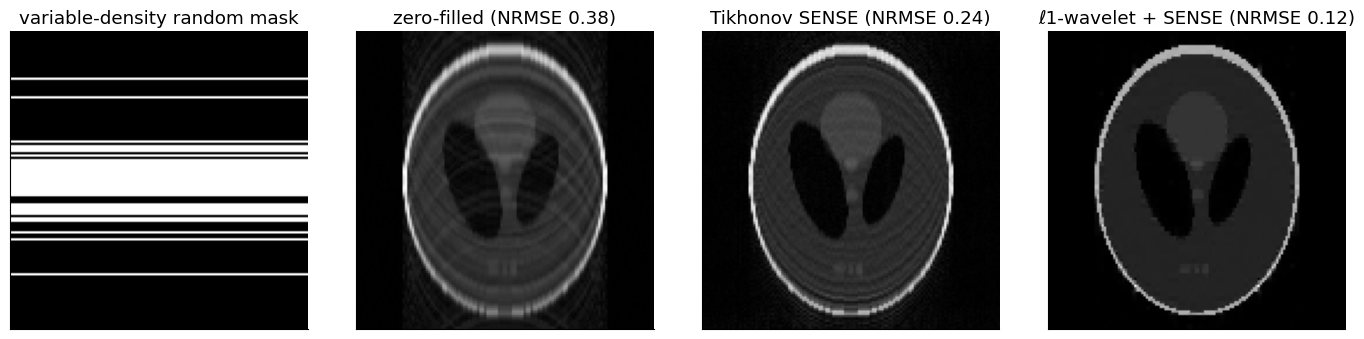

In [7]:
rng = np.random.default_rng(3)
ky = np.arange(N) - N // 2
prob = np.clip(0.85 * np.exp(-(ky / (0.14 * N)) ** 2) + 0.06, 0, 1)   # variable-density sampling probability
rows = rng.random(N) < prob
rows[N // 2 - 6:N // 2 + 6] = True                                   # fully sampled centre
mask_r = np.repeat(rows[:, None], N, axis=1).astype(float)
y_r = mask_r * mt.add_complex_noise(E(x_true, np.ones((N, N))), sigma, rng=np.random.default_rng(4))

x_zf_r = np.sqrt(np.sum(np.abs(mt.ifft2c(y_r)) ** 2, axis=0))
x_sense_r, _ = cg_sense(y_r, mask_r, lam=3e-3, n_iter=40)
x_cs, err_cs = fista_l1(y_r, mask_r, lam=4e-3, n_iter=150, x_ref=x_true)
print(f"acceleration R = {mask_r.size / mask_r.sum():.2f}")

fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
mt.show_image(mask_r, ax=ax[0], title="variable-density random mask")
mt.show_image(x_zf_r, ax=ax[1], title=f"zero-filled (NRMSE {nrmse(x_zf_r, x_true):.2f})")
mt.show_image(x_sense_r, ax=ax[2], title=f"Tikhonov SENSE (NRMSE {nrmse(x_sense_r, x_true):.2f})")
mt.show_image(x_cs, ax=ax[3], title=f"ℓ1-wavelet + SENSE (NRMSE {nrmse(x_cs, x_true):.2f})")
plt.tight_layout(); plt.show()

**Interpretation.** Random undersampling turns aliasing into noise-like streaks in the zero-filled image. SENSE alone (8 coils, $R\approx4$) already removes much of it, but noise amplification remains. Adding the ℓ1-wavelet term removes the incoherent artifacts and the noise, because neither is sparse in the wavelet domain, while the piecewise-constant object is. On real images the gain is smaller than on this idealized phantom, and too large a $\lambda_{CS}$ gives a "blocky" or cartoon-like look; that is the visible price of CS.

> **🔧 Engineering reality:** CS reconstructions are now standard on clinical scanners (vendor names such as Compressed SENSE, HyperSense, CS-SPACE). They are typically combined with parallel imaging and run on the scanner's reconstruction GPU in seconds. The tuning of $\lambda$ is fixed per protocol by the vendor.

## 5. Deep learning reconstructions

Deep learning (DL) methods can often be considered general solutions to a **regularized least-squares** objective:

$$\hat x_{reg} = \arg\min_x \tfrac12\,\lVert\mathbf y-\mathbf E x\rVert_2^2 + \mathcal R(x)$$

where $\mathcal R(\cdot)$ can be a parallel-imaging or compressed-sensing regularizer as above, but can also be implemented *implicitly* by a neural network. The deep-learning reconstruction is then a learned way to constrain or regularize the reconstruction.

**Image-domain networks.** The most direct approach trains a convolutional neural network (CNN) to undo aliasing and noise after an initial adjoint reconstruction:

$$\hat x_{DL} = g_{DNN}(\mathbf E^H\mathbf y)$$

The network $g_{DNN}$ has many weights that must be trained before it can reconstruct. It does not enforce data consistency, so it can produce images that look plausible but disagree with the measurements.

**Unrolled networks** are more popular for MRI reconstruction. They incorporate parallel imaging and data consistency explicitly and are often more compact. They mimic a fixed number of iterations of a classical algorithm (like FISTA above), and each iteration is "unrolled" into one block of a cascaded network. Popular examples:

* **Variational networks (VarNet):** each block is one gradient-descent step on the regularized objective, where the gradient of $\mathcal R$ is a CNN (e.g. a U-Net). The end-to-end VarNet also estimates the coil maps.
* **MoDL (model-based deep learning):** the regularizer is $\mathcal R_{MoDL}(x) = \lambda\lVert\mathcal N_w(x)\rVert^2$, where the CNN $\mathcal N_w$ with learned parameters $w$ estimates the noise and aliasing patterns. Each block alternates the CNN with a CG data-consistency step.

![End-to-end variational network](../images/end-to-end_varnet.jpg)

*An unrolled variational network (figure from the original book).*

The code below shows the **structure** of an unrolled reconstruction: a fixed number of "cascades", each made of a data-consistency gradient step and a denoising step. Here the denoiser is the fixed wavelet shrinkage from Section 4. In a real unrolled network, **each cascade's denoiser is a CNN with its own learned weights**, and the step sizes are learned too.

In [8]:
def unrolled_recon(y, mask, denoisers, steps):
    """Generic unrolled reconstruction: K cascades of (data-consistency step -> denoiser)."""
    x = EH(y, mask)                                   # initial guess = adjoint ("zero-filled")
    for denoise, t in zip(denoisers, steps):
        x = x - t * EH(E(x, mask) - y, mask)          # data consistency: gradient step on 1/2||y - Ex||^2
        x = denoise(x)                                # regularization: in a VarNet/MoDL this is a trained CNN
    return x

K = 12
wavelet_denoiser = lambda x: ihaar2(soft(haar2(x), 4e-3))
x_unrolled = unrolled_recon(y_r, mask_r, [wavelet_denoiser] * K, [1.0] * K)
print(f"{K}-cascade unrolled recon with a hand-made denoiser: NRMSE {nrmse(x_unrolled, x_true):.3f} "
      f"(FISTA, 150 iterations: {nrmse(x_cs, x_true):.3f})")

12-cascade unrolled recon with a hand-made denoiser: NRMSE 0.246 (FISTA, 150 iterations: 0.117)


**Interpretation.** With a hand-made denoiser and fixed steps, 12 cascades get only part of the way to the converged ℓ1 result (compare the two printed errors): a generic regularizer needs many iterations. This is exactly what training fixes. Learned denoisers and step sizes, tuned to real anatomy and to the sampling pattern, let a small number of cascades (typically 8–12) give images as good as or better than hundreds of classical iterations, in a fraction of the time.

> **⚠️ Common confusion:** "The network fills in missing data" is only half the story. Data consistency keeps the result faithful to what was measured, but anything that was *not* measured comes from the training data. DL reconstructions can **hallucinate** realistic-looking structures or remove small real lesions. They must be validated carefully on the type of images (and pathologies) they will be used for.

### 5.1 Deep learning requirements

1. **Data**
    * Generally a lot of data (on the order of $10^4$ examples in many radiology applications, but this depends strongly on the question and data quality).
    * Fully sampled data are typically required for *supervised* learning of undersampled reconstruction.
    * Data augmentation: realistic modifications of existing data to increase the training set.
    * For reconstruction, the fastMRI project provides thousands of high-quality raw datasets: http://fastmri.med.nyu.edu, https://doi.org/10.48550/arXiv.1811.08839
2. **Architecture**
    * U-Net and ResNet are popular for image-domain networks.
    * Unrolled networks are popular for image reconstruction.
    * Generative models (e.g. diffusion models) and transformers are increasingly used.
3. **Computation**
    * GPUs are essential for training deep networks.
4. **Training**
    * Send input data forward through the network, compare with the expected output (e.g. the fully sampled image or data), and update the weights by back-propagation.
    * Choose a loss function, such as ℓ1 or ℓ2 (or perceptual/SSIM losses).
    * Choose batch size, learning rate, etc.

## 6. Summary: one framework, many methods

| Method | Encoding $\mathbf E$ | Regularizer | Solver |
|---|---|---|---|
| Fourier recon | $\mathbf F$ | none | inverse FFT |
| SENSE | $\mathbf S\mathbf F\mathbf C_q$ | none or $\lambda\lVert x\rVert_2^2$ | direct unfolding or CG |
| GRAPPA / SPIRiT | $\mathbf S\mathbf F$ (per coil) | $\lambda\lVert(\mathbf G-\mathbf I)x\rVert_2^2$ (calibration consistency) | direct kernel / CG |
| Compressed sensing (+PI) | $\mathbf S\mathbf F\mathbf C_q$ | $\lambda_{CS}\lVert\mathbf W x\rVert_1$ | ISTA/FISTA, ADMM |
| Deep learning (unrolled) | $\mathbf S\mathbf F\mathbf C_q$ | learned $\mathcal R$ (CNN) | K learned cascades |

## Key takeaways

* MRI reconstruction can be written as the linear inverse problem $\mathbf y=\mathbf E x+\mathbf n$, with the encoding operator $\mathbf E$ derived from the signal equation.
* For full Cartesian sampling, $\mathbf E$ is a DFT and $\hat x = \mathbf F^H y / N_{pix}$ (or simply $\mathbf F^H y$ with unitary scaling) is computed by the FFT.
* $\mathbf E$ is never stored; iterative methods only need functions that apply $\mathbf E$ and $\mathbf E^H$. Always run an **adjoint test**.
* SENSE is a least-squares fit solved by unfolding or **conjugate gradients**; regularization trades noise against bias.
* Compressed sensing adds a **sparsity** term $\lambda\lVert\mathbf Wx\rVert_1$ and requires **incoherent** (random-like) undersampling; FISTA solves it with gradient steps plus soft-thresholding.
* Unrolled deep-learning methods are iterative algorithms with **learned regularization steps**; they need large training datasets and careful validation against hallucinations.

## Check your understanding

1. The original text gives the Fourier reconstruction as $\hat x = \mathbf F^H y$. When is this exactly right, and what is missing otherwise?

<details><summary>Answer</summary>

It is exact when $\mathbf F$ is normalized to be unitary ($\mathbf F/\sqrt{N_{pix}}$, as in `norm="ortho"`). With the plain DFT matrix $\mathbf F_{i,j}=e^{-i2\pi\vec k_i\cdot\vec r_j}$ one has $\mathbf F^H\mathbf F=N_{pix}\mathbf I$, so the inverse is $\mathbf F^H y/N_{pix}$.

</details>

2. Why is $\mathbf C_q$ a diagonal matrix, and what does that mean for computing $\mathbf E x$?

<details><summary>Answer</summary>

The coil sensitivity multiplies the magnetization pixel by pixel: the signal from pixel $j$ is weighted by $C_q(\vec r_j)$ and does not mix with other pixels. A diagonal matrix applied to a vector is just element-wise multiplication, so $\mathbf E_q x$ = element-wise product with the coil map, then FFT, then keep the sampled entries.

</details>

3. Compressed sensing uses random undersampling, while SENSE in Section 3.1 used regular (every 3rd line) undersampling. Why?

<details><summary>Answer</summary>

Regular undersampling produces **coherent** aliasing: shifted copies of the object, which look just as "sparse" as the object itself, so a sparsity penalty cannot tell them apart. Coil sensitivities *can*, which is why SENSE likes regular sampling. Random undersampling spreads the aliasing into **incoherent** noise-like artifacts that are not sparse, so the ℓ1 term suppresses them while keeping the sparse image.

</details>

4. In the λ sweep, why does the error first decrease and then increase as λ grows?

<details><summary>Answer</summary>

Small λ: the solution follows the data closely, including amplified noise (high variance). As λ grows, noise is suppressed. Too large λ: the penalty dominates and pulls the image toward zero (or toward the regularizer's preferred image), biasing intensities and contrast. The best λ balances variance and bias.

</details>

5. What is the difference between an image-domain network $g_{DNN}(\mathbf E^H\mathbf y)$ and an unrolled network?

<details><summary>Answer</summary>

The image-domain network sees the data only once, through the adjoint, and never checks its output against the measurements. An unrolled network alternates learned regularization blocks with **data-consistency** steps that use the physical model $\mathbf E$ (including coil maps and the sampling mask), so its output stays consistent with what was measured. It also generalizes better to new sampling patterns and needs fewer parameters.

</details>

### Reference

For a recent, comprehensive reference on these methods:

Hammernik K, Küstner T, Yaman B, Huang Z, Rueckert D, Knoll F, Akçakaya M. Physics-Driven Deep Learning for Computational Magnetic Resonance Imaging: Combining physics and machine learning for improved medical imaging. *IEEE Signal Process Mag.* 2023;40(1):98–114. doi:10.1109/msp.2022.3215288. https://arxiv.org/pdf/2203.12215.pdf

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Advanced Image Reconstruction". Changes: all symbols defined; the missing $1/N_{pix}$ factor of the Fourier inverse explained; runnable implementations of the encoding operators (with adjoint test), CG-SENSE with Tikhonov regularization, ℓ1-wavelet compressed sensing (FISTA) and an unrolled-reconstruction skeleton added; summary table.*